In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

In [2]:
plots = Path("plots") / "other"

In [3]:
N = 1000
M = 1000
S = [0.2, 0.1, 0.05]

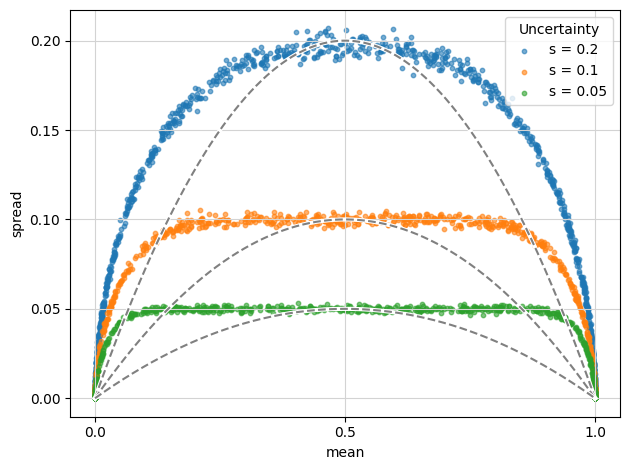

In [4]:
fig, ax = plt.subplots()

ax.set_xlabel("mean")
ax.set_xticks([0.0, 0.5, 1.0])
ax.set_ylabel("spread")

rng = np.random.default_rng(seed=42)

for s in S:
    x = rng.random(size=N) * 2 - 0.5
    x_hat = x.reshape(N, 1) + rng.standard_normal(size=(N, M)) * s
    y = np.clip(x_hat, 0, 1)

    mean = np.mean(y, axis=1)
    spread = np.std(y, axis=1)

    ax.scatter(mean, spread, s=10, alpha=0.6, label=f"s = {s}")

x = np.linspace(0, 1, 1000)

for s in S:
    ax.plot(x, 4 * s * x * (1 - x), c="white", lw=3)
    ax.plot(x, 4 * s * x * (1 - x), c="gray", ls="--")

ax.legend(loc="upper right", title="Uncertainty")
ax.grid(c="lightgray")

plt.tight_layout()

plt.show()
fig.savefig(plots / "quadratic-theory.pdf")